In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression 

In [2]:
df = pd.read_csv('./diabetes.csv')
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
df['Outcome'].value_counts()

0    500
1    268
Name: Outcome, dtype: int64

In [4]:
def get_clf_eval(y_test, pred = None, pred_proba= None) :
    confusion = confusion_matrix(y_test, pred)
    accuracy = accuracy_score(y_test, pred)
    precision = precision_score(y_test, pred)
    recall = recall_score(y_test, pred)
    f1 = f1_score(y_test, pred)
    roc_auc = roc_auc_score(y_test, pred_proba)

    print('오차행렬')
    print(confusion)
    print('정확도 :', accuracy)
    print('정밀도 :', precision)
    print('재현율 :', recall)
    print('f1 :', f1)
    print('roc_auc :', roc_auc)

In [6]:
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state=42, stratify=y) 

# stratify = y 균등하게 y에 나누기

In [8]:
lr_clf = LogisticRegression(solver= 'liblinear')
lr_clf.fit(X_train, y_train)
pred = lr_clf.predict(X_test)
pred_proba = lr_clf.predict_proba(X_test)[:,1]

get_clf_eval(y_test, pred, pred_proba)

오차행렬
[[85 15]
 [27 27]]
정확도 : 0.7272727272727273
정밀도 : 0.6428571428571429
재현율 : 0.5
f1 : 0.5625000000000001
roc_auc : 0.8287037037037037


In [9]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


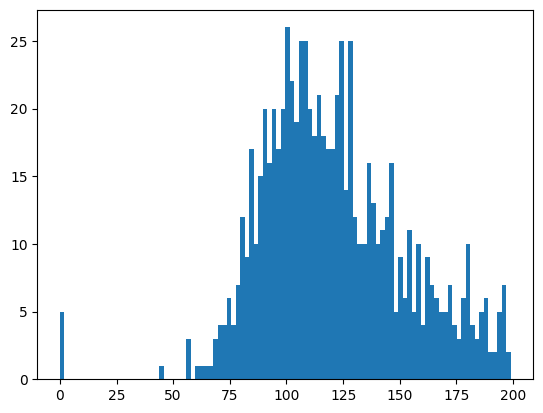

In [10]:
plt.hist(df['Glucose'], bins= 100)
plt.show()

In [12]:
zero_features = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

total_count = df['Glucose'].count()

for feature in zero_features :
    zero_count = df[df[feature] == 0][feature].count()
    print(feature, zero_count, 100 * zero_count/total_count)

Glucose 5 0.6510416666666666
BloodPressure 35 4.557291666666667
SkinThickness 227 29.557291666666668
Insulin 374 48.697916666666664
BMI 11 1.4322916666666667


In [ ]:
scaler = StandardScaler()
# fit 또는 fit_transform은 딱 한번 쓸 수 있음 : 재학습 경우 재사용 가능
# X_traindp fit 했으면 X_test는 무조건 transform만 해야함
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2,
                                                    random_state=42, stratify=y)
# 스케일링한 후에 모델 재학습

lr_clf.fit(X_train, y_train)
pred = lr_clf.predict(X_test)
pred_proba = lr_clf.predict_proba(X_test)[:, 1]

get_clf_eval(y_test, pred, pred_proba)


오차행렬
[[82 18]
 [26 28]]
정확도 : 0.7142857142857143
정밀도 : 0.6086956521739131
재현율 : 0.5185185185185185
f1 : 0.5599999999999999
roc_auc : 0.8229629629629629


In [ ]:
# 임계값에 따른 성능 평과 지표
from sklearn.preprocessing import Binarizer

def get_eval_by_threshold(y_test, pred_proba_c1, thresholds):
    for custom_threshold in thresholds:
        binarizer = Binarizer(threshold = custom_threshold).fit(pred_proba_c1)
        custom_pred = binarizer.transform(pred_proba_c1)
        print("임계값 :", custom_threshold)
        get_clf_eval(y_test, custom_pred, pred_proba_c1)

In [20]:
thresholds = [0.3, 0.33, 0.36, 0.39, 0.42, 0.45, 0.48, 0.50]
pred_proba = lr_clf.predict_proba(X_test)[:, 1]
get_eval_by_threshold(y_test, pred_proba.reshape(-1, 1), thresholds)

임계값 : 0.3
오차행렬
[[70 30]
 [10 44]]
정확도 : 0.7402597402597403
정밀도 : 0.5945945945945946
재현율 : 0.8148148148148148
f1 : 0.6875
roc_auc : 0.8229629629629629
임계값 : 0.33
오차행렬
[[73 27]
 [13 41]]
정확도 : 0.7402597402597403
정밀도 : 0.6029411764705882
재현율 : 0.7592592592592593
f1 : 0.6721311475409837
roc_auc : 0.8229629629629629
임계값 : 0.36
오차행렬
[[77 23]
 [16 38]]
정확도 : 0.7467532467532467
정밀도 : 0.6229508196721312
재현율 : 0.7037037037037037
f1 : 0.6608695652173914
roc_auc : 0.8229629629629629
임계값 : 0.39
오차행렬
[[78 22]
 [18 36]]
정확도 : 0.7402597402597403
정밀도 : 0.6206896551724138
재현율 : 0.6666666666666666
f1 : 0.6428571428571429
roc_auc : 0.8229629629629629
임계값 : 0.42
오차행렬
[[78 22]
 [22 32]]
정확도 : 0.7142857142857143
정밀도 : 0.5925925925925926
재현율 : 0.5925925925925926
f1 : 0.5925925925925926
roc_auc : 0.8229629629629629
임계값 : 0.45
오차행렬
[[79 21]
 [22 32]]
정확도 : 0.7207792207792207
정밀도 : 0.6037735849056604
재현율 : 0.5925925925925926
f1 : 0.5981308411214954
roc_auc : 0.8229629629629629
임계값 : 0.48
오차행렬
[[81 19]
 [26 28]]
